
# Notebook 2 — A New Algorithm Family, and Learning Without Labels

**Course:** Machine Learning in Astronomy — Week 2 Pre-Work Notebook
**Audience:** MSc/PhD students in Astronomy, Space Science, Solar Physics, Cosmology

## Bridge from Notebook 1

Everything in Notebook 1 assumed you already had correct labels to learn from — a spectroscopically-confirmed redshift, a confirmed object type. This notebook makes two moves. First, a gentle one: a new family of algorithms (decision trees and random forests) that's still supervised, still uses labels, but works completely differently from anything in Notebook 1 — no gradient descent, no sigmoid, just a sequence of yes/no questions. Second, the real conceptual leap: **what do you do when you don't have labels at all, or only a handful?**

This matters in astronomy specifically for an economic reason, not an abstract one: getting a photometric measurement (a brightness in a few filters) is comparatively cheap; getting a spectroscopically-confirmed label is expensive telescope time. Every large survey has vastly more unlabeled data than labeled data, by construction. Unsupervised and semi-supervised learning exist because of that gap.

## Learning objectives

By the end of this notebook you should be able to:
- Explain how a decision tree makes a prediction, and why a random forest tends to generalize better than any single tree
- Explain why "no labels" changes what evaluation even means, and know at least two ways to still say something honest about a clustering result
- Fit and interpret K-means and Gaussian Mixture Model clustering
- Use PCA to reduce dimensionality and explain what "explained variance" means
- Explain the self-training algorithm for semi-supervised learning, including its real risk (confirmation bias)
- Flag anomalies with no labels at all, using two different, disagreeing notions of "unusual"

## Table of contents
1. A new algorithm family: decision trees & random forests
2. What changes when you don't have labels?
3. Clustering: K-means and Gaussian Mixture Models
4. Dimensionality reduction: PCA
5. Semi-supervised learning: self-training
6. Unsupervised anomaly detection
7. Self-check questions


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



### The data (same real source as Notebook 1, for continuity)

Real SDSS17 photometry, real spectroscopically-confirmed classes and redshifts — 100,000 real objects. We'll keep the true labels sitting quietly in a column throughout this notebook, using them only where explicitly flagged as an honest "peek" to check our unsupervised results, exactly as a real researcher would use a small labeled validation subset to sanity-check an otherwise unsupervised pipeline.


In [2]:

url = "https://raw.githubusercontent.com/CodeByPinar/Stellar-Sleuth/main/star_classification.csv"
sdss = pd.read_csv(url)
sdss = sdss[(sdss[['u', 'g', 'r', 'i', 'z']] > -100).all(axis=1)].copy()

sdss['u_g'] = sdss['u'] - sdss['g']
sdss['g_r'] = sdss['g'] - sdss['r']
sdss['r_i'] = sdss['r'] - sdss['i']
sdss['i_z'] = sdss['i'] - sdss['z']

sample = sdss.sample(n=8000, random_state=42).reset_index(drop=True)
feature_cols = ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z']
print(sample['class'].value_counts())
sample[feature_cols + ['class', 'redshift']].head()


class
GALAXY    4777
STAR      1724
QSO       1499
Name: count, dtype: int64


,u,g,r,i,z,u_g,g_r,r_i,i_z,class,redshift
0,22.85773,22.18874,21.35562,21.26577,20.93935,0.66899,0.83312,0.08985,0.32642,QSO,1.174289
1,22.62560,22.02104,22.06787,22.44037,22.17338,0.60456,-0.04683,-0.37250,0.26699,STAR,-0.001960
2,18.18911,16.89469,16.42161,16.24627,16.18549,1.29442,0.47308,0.17534,0.06078,STAR,0.000004
3,17.57887,16.55078,16.21527,16.10371,16.09738,1.02809,0.33551,0.11156,0.00633,STAR,-0.000165
4,27.10401,22.65568,21.26362,20.04805,19.61308,4.44833,1.39206,1.21557,0.43497,GALAXY,0.523852



## 1. A New Algorithm Family: Decision Trees & Random Forests

### The idea, in plain language
Every model so far has been built from smooth mathematical functions — a weighted sum, a sigmoid. A **decision tree** does something completely different: it asks a sequence of yes/no questions about your features, like a flowchart. "Is $g - r > 1.2$? If yes, is $u - g > 2.0$? ..." — each question splits the data into smaller, more homogeneous groups, and the final answer (a class, or a predicted number) comes from whichever group you land in after following the questions down to a leaf.

### How the tree decides which question to ask
At each step, the tree tries every possible feature and threshold, and picks whichever split makes the resulting groups *least mixed*. The standard way to measure "how mixed" a group is, is **Gini impurity**:
$$Gini = 1 - \sum_{k} p_k^2$$
where $p_k$ is the fraction of the group belonging to class $k$. A perfectly pure group (everything the same class) has $Gini = 0$; a group evenly split between classes has a high Gini. The tree greedily picks the split that reduces the (weighted) Gini impurity the most.

### The problem with a single tree, and how random forests fix it
A single tree grown deep enough can perfectly memorize its training data — a textbook case of the overfitting you saw in Notebook 0 §8. A **random forest** builds many trees, each on a random bootstrap sample of the training data and a random subset of features at each split, then has them **vote** (classification) or **average** (regression). This is called **bagging**. The intuition: individual trees are high-variance (small changes in training data can produce very different trees), but the *average* of many independently-wrong-in-different-directions trees has much lower variance — the same bias-variance idea from Notebook 0, now solved by averaging instead of by choosing a simpler model.

### What the code below will do
We'll fit a shallow decision tree on just two features and actually **look at the tree itself** — a genuinely concrete way to see what "the model" is, rather than treating it as a black box — then compare a full decision tree and a random forest against the fuller feature set, benchmarked directly against Notebook 1's best result (a 12-feature logistic regression that reached 63% accuracy on this same 3-class problem).


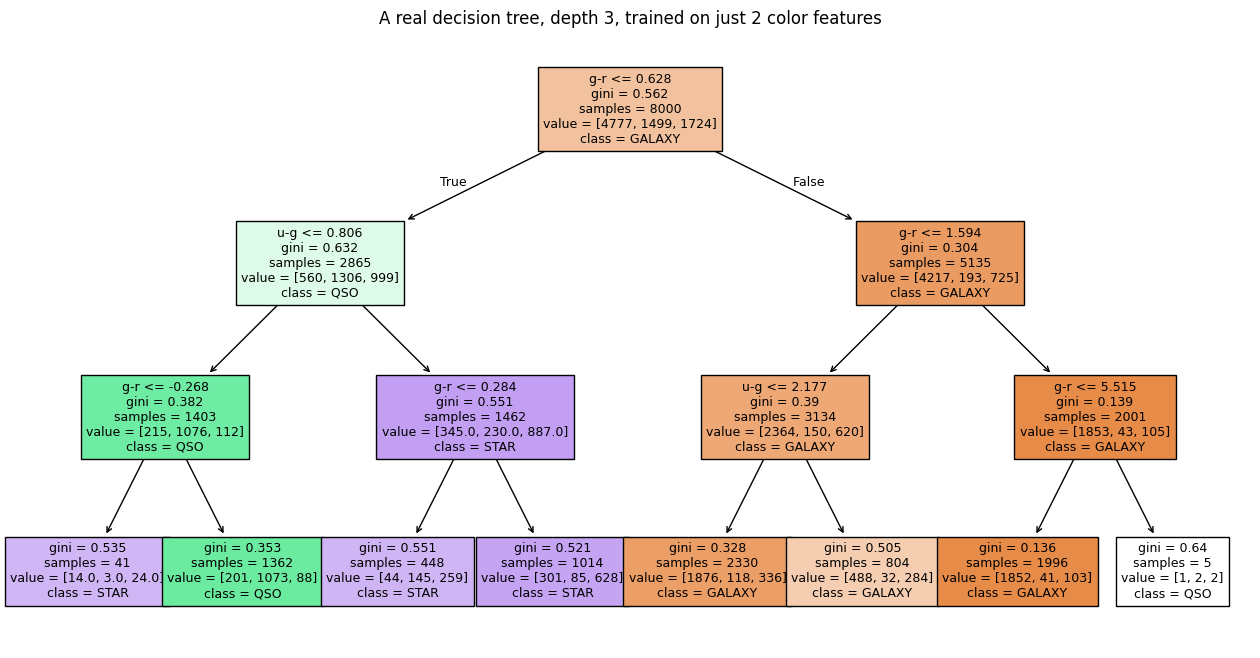

In [3]:

# A shallow, visualizable tree first
X_shallow = sample[['g_r', 'u_g']].values
y = sample['class'].values

tree_shallow = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_shallow.fit(X_shallow, y)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_shallow, feature_names=['g-r', 'u-g'], class_names=tree_shallow.classes_,
          filled=True, fontsize=9, ax=ax)
plt.title('A real decision tree, depth 3, trained on just 2 color features')
plt.show()



Read this like a flowchart from the top: each box asks a yes/no question about one feature, `gini` tells you how mixed that group still is, and `value` shows the class counts at that point. Follow any path from the top box to a leaf — that's the exact sequence of questions the tree asks about a new object to classify it.

**🔧 Try it yourself:** change `max_depth=3` to `max_depth=1` (a "decision stump" — just one question) and re-run. Look at how much of the 3-class structure a single yes/no question can and can't capture.


In [4]:

# Now the fuller comparison: single tree vs. random forest, richer features
X = sample[feature_cols].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

tree_full = DecisionTreeClassifier(max_depth=8, random_state=42)
tree_full.fit(X_train, y_train)
tree_acc = accuracy_score(y_test, tree_full.predict(X_test))

forest = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
forest.fit(X_train, y_train)
forest_acc = accuracy_score(y_test, forest.predict(X_test))

print(f"Single decision tree accuracy: {tree_acc:.3f}")
print(f"Random forest accuracy:        {forest_acc:.3f}")
print("(Notebook 1's best logistic regression, same 3-class problem, 12 features: 0.634)")


Single decision tree accuracy: 0.858
Random forest accuracy:        0.871
(Notebook 1's best logistic regression, same 3-class problem, 12 features: 0.634)



**Interpretation:** the random forest should meaningfully beat both the single tree and Notebook 1's logistic regression — direct, real evidence that tree-based methods handle this kind of tabular, non-linearly-separable astronomical data well, exactly as flagged as a forward-pointer at the end of Notebook 1.

### Feature importance — useful, but read it carefully


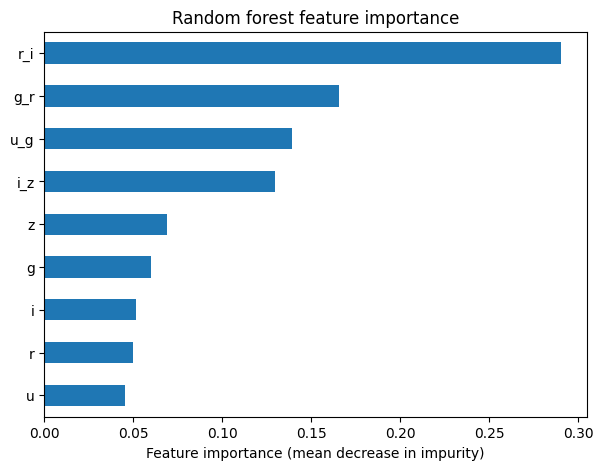

r_i    0.290
g_r    0.166
u_g    0.139
i_z    0.129
z      0.069
g      0.060
i      0.051
r      0.050
u      0.045
dtype: float64


In [5]:

importances = pd.Series(forest.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
importances.plot(kind='barh', ax=ax)
ax.set_xlabel('Feature importance (mean decrease in impurity)')
ax.set_title('Random forest feature importance')
ax.invert_yaxis()
plt.show()
print(importances.round(3))



**A real caveat, not a footnote:** notice that raw magnitudes and colors built from those same magnitudes are correlated by construction (e.g. `g` and `g_r` share information). When features are correlated, a tree can use *either one* to make a similar split, so importance gets arbitrarily split between them — a feature isn't necessarily unimportant just because it scores low here, it might be redundant with another feature that's soaking up the credit. Feature importance tells you what the model *used*, not definitively what's *causally* informative.

**🔧 Try it yourself:** drop all four color columns and refit the random forest on raw magnitudes alone — check whether accuracy drops much. If it barely changes, that's a sign colors and magnitudes were carrying overlapping information.

### The overfitting pattern, again, in a completely different algorithm


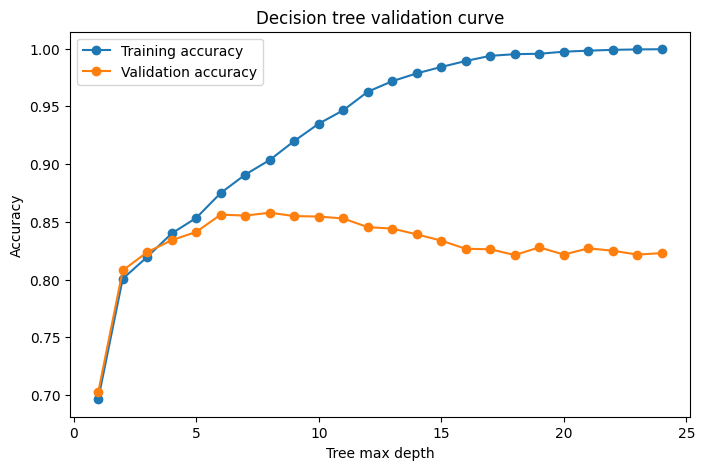

In [6]:

depths = range(1, 25)
train_acc, val_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    t.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, t.predict(X_train)))
    val_acc.append(accuracy_score(y_test, t.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(depths, train_acc, marker='o', label='Training accuracy')
ax.plot(depths, val_acc, marker='o', label='Validation accuracy')
ax.set_xlabel('Tree max depth'); ax.set_ylabel('Accuracy')
ax.set_title('Decision tree validation curve')
ax.legend()
plt.show()



**🔧 Try it yourself:** find the depth where the two curves start to visibly diverge — that's the tree beginning to memorize training-set quirks rather than learning general structure, the exact same overfitting signature as Notebook 1's k-NN validation curve, just with a completely different "complexity knob" (depth instead of $k$). The *pattern* is what transfers across algorithms, not the specific knob.



## 2. What Changes When You Don't Have Labels?

Every method in Notebook 1 and Section 1 above needed a `y` — a known correct answer for every training example. From here on, imagine that column doesn't exist. This isn't a hypothetical: it's the normal situation for most astronomical data ever collected.

| Subfield | A real unsupervised task |
|---|---|
| Stellar astronomy | Discovering natural stellar populations in a color-magnitude diagram, with no predefined categories |
| Solar physics | Grouping solar wind measurements into regime types (fast wind, slow wind, coronal-mass-ejection material) with no labels |
| Cosmology | Finding structure — clusters, filaments, voids — in a galaxy catalog's spatial distribution |
| Space science | Grouping unlabeled satellite telemetry into normal operating modes, so genuinely new modes stand out |

The immediate hard question **evaluation** raises: without a `y_true` to compare against, what does "the model did well" even mean? Sections 3-6 keep coming back to this.

**🔧 Try it yourself (no code needed):** for each task in the table, write down what you *would* check if someone handed you the clustering result and asked "did this work?" — before reading Section 3, where we'll do exactly that.



## 3. Clustering: K-Means and Gaussian Mixture Models

### K-means, the idea before the formula
Pick $k$ points as initial "centers." Assign every data point to its nearest center. Recompute each center as the average of the points assigned to it. Repeat until nothing changes. Formally, K-means minimizes the total squared distance from each point to its assigned center:
$$J = \sum_{k} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$
This is a **hard** assignment — every point belongs to exactly one cluster.

### Gaussian Mixture Models: the soft generalization
A GMM assumes the data was generated by a mixture of several Gaussian distributions (directly building on Notebook 0 Sections 4-5's covariance and joint-Gaussian ideas) and assigns every point a **probability** of belonging to each cluster, rather than a hard label. This matters when clusters genuinely overlap — which real astronomical populations often do.

### The honest evaluation trick we get to use here (and why real problems usually don't)
We're about to cluster real SDSS objects using *only* their colors — no class labels involved in the fitting. But because this is a teaching dataset, we secretly still have the true classes sitting in `sample['class']`. We'll use them **after the fact**, purely to check how well the discovered clusters line up with real categories — a validation luxury a genuinely unlabeled problem won't have. Name this explicitly every time you do it in your own research: it's a sanity check on a small labeled subset, not a general evaluation method for the unlabeled majority of your data.


In [7]:

color_features = ['u_g', 'g_r', 'r_i', 'i_z']
Xc = StandardScaler().fit_transform(sample[color_features].values)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(Xc)

gmm = GaussianMixture(n_components=3, random_state=42)
gmm_labels = gmm.fit_predict(Xc)

print("K-means cluster sizes:", np.bincount(kmeans_labels))
print("GMM cluster sizes:    ", np.bincount(gmm_labels))


K-means cluster sizes: [1649 3707 2644]
GMM cluster sizes:     [3197 3798 1005]


In [8]:

# The "peek": how well do the discovered clusters line up with the real classes?
contingency = pd.crosstab(sample['class'], kmeans_labels, rownames=['true class'], colnames=['k-means cluster'])
print(contingency)
print(f"\nAdjusted Rand Index (K-means vs. true class): {adjusted_rand_score(sample['class'], kmeans_labels):.3f}")
print(f"Adjusted Rand Index (GMM vs. true class):     {adjusted_rand_score(sample['class'], gmm_labels):.3f}")
print("\n(ARI = 0 means no better than random agreement, ARI = 1 means perfect agreement with the true classes.)")


k-means cluster     0     1     2
true class                       
GALAXY           1399  1153  2225
QSO                49  1384    66
STAR              201  1170   353

Adjusted Rand Index (K-means vs. true class): 0.092
Adjusted Rand Index (GMM vs. true class):     0.126

(ARI = 0 means no better than random agreement, ARI = 1 means perfect agreement with the true classes.)



**Interpretation, with the real numbers in hand:** an ARI of roughly 0.09-0.13 is modest — genuinely above zero (so not random noise), but nowhere close to the 1.0 you'd get from perfect agreement with the true classes. Read this honestly rather than rounding it either up to "clustering basically works" or down to "clustering failed": with zero label information, K-means and GMM found *some* real structure that lines up with the true classes, but color space alone clearly isn't enough to cleanly separate stars, galaxies, and quasars into three neat groups — look back at the contingency table above and you'll see plenty of cross-contamination between clusters. Real astronomical populations often do overlap substantially in whatever feature space you happen to choose, and a small positive ARI is frequently the honest, correct answer rather than a sign something went wrong.

### Choosing $k$ without knowing the true number of classes
In a real unlabeled problem, you don't get to check against ground truth like we just did. Two standard label-free ways to choose $k$:


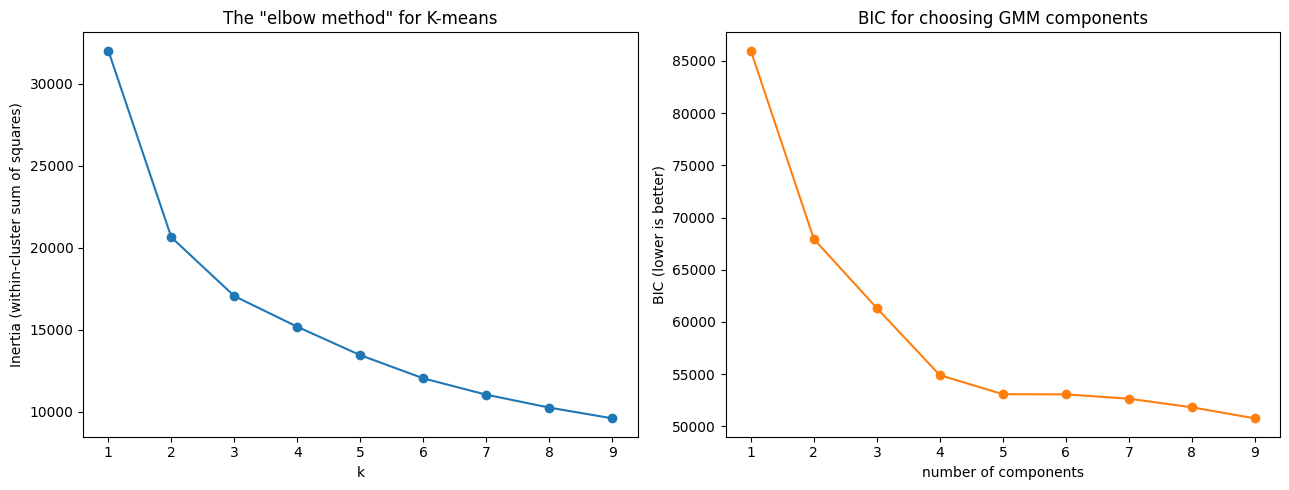

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

inertias = []
k_range = range(1, 10)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc)
    inertias.append(km.inertia_)
axes[0].plot(k_range, inertias, marker='o')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('The "elbow method" for K-means')

bics = []
for k in k_range:
    g = GaussianMixture(n_components=k, random_state=42).fit(Xc)
    bics.append(g.bic(Xc))
axes[1].plot(k_range, bics, marker='o', color='C1')
axes[1].set_xlabel('number of components'); axes[1].set_ylabel('BIC (lower is better)')
axes[1].set_title('BIC for choosing GMM components')

plt.tight_layout()
plt.show()



**Interpretation:** the "elbow" is the point where adding another cluster stops giving you much additional improvement — look for where the inertia curve visibly bends, not where it's lowest (it's always lowest at the largest $k$, which is a meaningless answer). The BIC curve should have an actual minimum; that's the GMM's suggested number of components. Neither method needed the true labels at all.

**🔧 Try it yourself:** re-run this section's clustering using raw magnitudes (`['u','g','r','i','z']`) instead of colors — compare the resulting ARI. This directly tests whether the feature-choice lesson from Notebook 1 (colors carry more discriminating information than raw magnitudes) also holds for a completely unsupervised method.


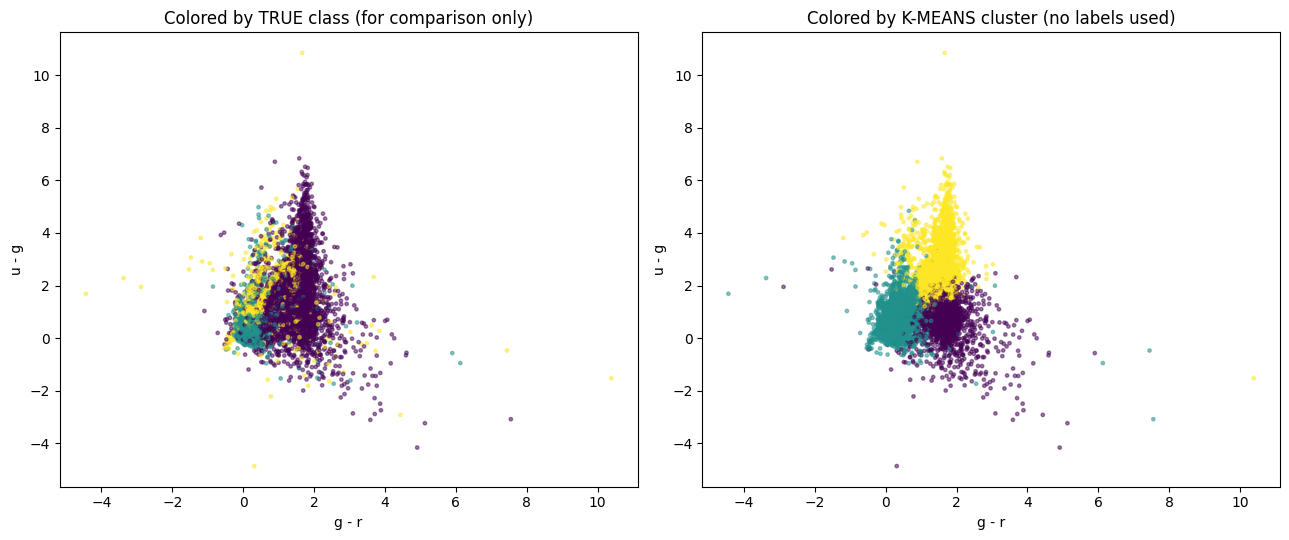

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
class_codes = sample['class'].astype('category').cat.codes
for ax, labels, title in zip(axes, [class_codes, kmeans_labels],
                              ['Colored by TRUE class (for comparison only)', 'Colored by K-MEANS cluster (no labels used)']):
    sc = ax.scatter(sample['g_r'], sample['u_g'], c=labels, cmap='viridis', s=6, alpha=0.5)
    ax.set_xlabel('g - r'); ax.set_ylabel('u - g')
    ax.set_title(title)
plt.tight_layout()
plt.show()



## 4. Dimensionality Reduction: PCA

### The direct callback to Notebook 0
Notebook 0 Section 4 found the eigenvectors of a covariance matrix and called them "the natural axes of the data cloud." **Principal Component Analysis (PCA) is that exact idea, used as a full technique**: project your data onto the top few eigenvectors (by eigenvalue, i.e. by how much variance they capture), and you get a lower-dimensional representation that keeps as much of the original structure as possible.

### Explained variance
Each principal component comes with an **explained variance ratio** — what fraction of the total spread in the data that one direction accounts for. Plotting these, and their cumulative sum, answers the practical question "how many components do I actually need to keep?"


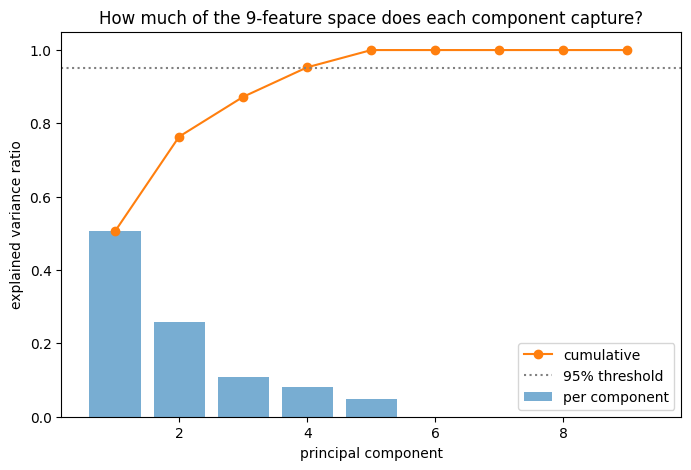

Cumulative variance explained: [0.506 0.764 0.872 0.953 1.    1.    1.    1.    1.   ]


In [11]:

Xp = StandardScaler().fit_transform(sample[feature_cols].values)
pca = PCA()
pca.fit(Xp)

fig, ax = plt.subplots(figsize=(8, 5))
cum_var = np.cumsum(pca.explained_variance_ratio_)
ax.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.6, label='per component')
ax.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='C1', label='cumulative')
ax.axhline(0.95, color='gray', linestyle=':', label='95% threshold')
ax.set_xlabel('principal component'); ax.set_ylabel('explained variance ratio')
ax.set_title('How much of the 9-feature space does each component capture?')
ax.legend()
plt.show()
print("Cumulative variance explained:", np.round(cum_var, 3))



### Looking at the reduced space — in 3D, colored by the real redshift


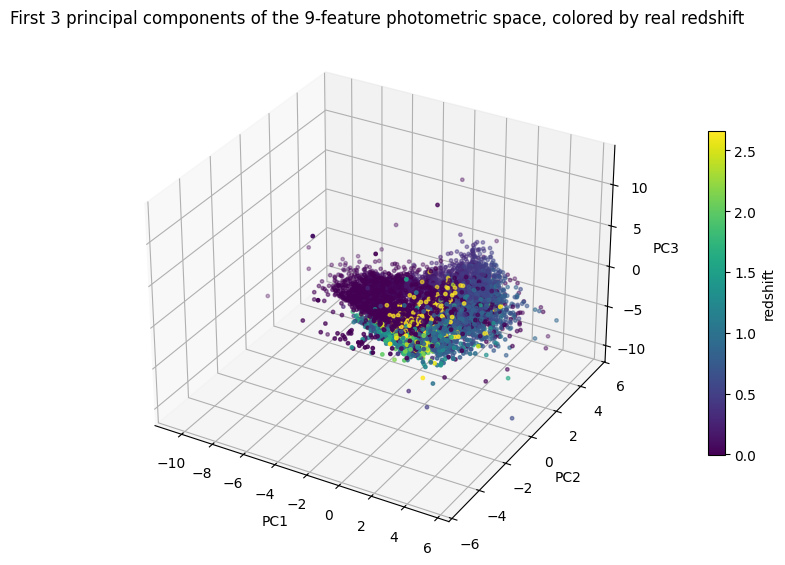

In [12]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(Xp)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X_pca3[:, 0], X_pca3[:, 1], X_pca3[:, 2], c=sample['redshift'],
                 cmap='viridis', s=6, vmax=np.percentile(sample['redshift'], 98))
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
ax.set_title('First 3 principal components of the 9-feature photometric space, colored by real redshift')
fig.colorbar(sc, ax=ax, shrink=0.6, label='redshift', pad=0.1)
plt.show()



**Interpretation:** we never told PCA anything about redshift — it only ever saw the 9 photometric features. If the color gradient still looks organized rather than random across this 3D projection, that's a genuine, non-trivial result: it means most of the redshift-relevant information in the original 9 features survives being compressed down to just 3 dimensions.

### How much do you lose by keeping fewer components?


In [13]:

for n_comp in [1, 2, 3, 5, 9]:
    pca_n = PCA(n_components=n_comp)
    X_reduced = pca_n.fit_transform(Xp)
    X_reconstructed = pca_n.inverse_transform(X_reduced)
    reconstruction_error = np.mean((Xp - X_reconstructed) ** 2)
    print(f"{n_comp} component(s): reconstruction MSE = {reconstruction_error:.4f}, "
          f"variance explained = {np.sum(pca_n.explained_variance_ratio_):.3f}")


1 component(s): reconstruction MSE = 0.4941, variance explained = 0.506
2 component(s): reconstruction MSE = 0.2361, variance explained = 0.764
3 component(s): reconstruction MSE = 0.1275, variance explained = 0.872
5 component(s): reconstruction MSE = 0.0000, variance explained = 1.000
9 component(s): reconstruction MSE = 0.0000, variance explained = 1.000



**🔧 Try it yourself:** redo the 3D plot above using just `n_components=3` fit on **raw magnitudes alone** (no colors) — does the redshift gradient look as organized? This is the same "which features actually carry the information" question from Section 3, now asked of PCA instead of clustering.

**One more thing worth noticing in the numbers above:** reconstruction error hits exactly zero at 5 components, not 9 — even though we started with 9 features. That's not a coincidence or a bug: the four color columns (`u_g`, `g_r`, `r_i`, `i_z`) are each just a *subtraction* of two magnitude columns already in the feature set, so they contain zero information beyond what the 5 raw magnitudes already carry. PCA is quietly telling you the truth about your own feature engineering here — we added four columns that felt like new information but were, mathematically, a rotation of information already present. This doesn't make colors useless (a model can still learn faster or generalize better with the right rotation handed to it explicitly), but it's a genuinely different claim than "colors add new information."



## 5. Semi-Supervised Learning: Self-Training

### The realistic scenario
Say you have 2% of your sample spectroscopically confirmed, and the other 98% only has photometry. Throwing away the 98% feels wasteful - surely it contains *some* useful signal, even without labels. **Self-training** is the simplest way to try to use it:

1. Train a classifier on the small labeled set.
2. Use it to predict on the unlabeled pool, keeping the predicted *probabilities*.
3. Take the most confident predictions (say, probability > 0.95) and add them to the training set **as if they were true labels**.
4. Retrain, and repeat.

### The real risk, named plainly: confirmation bias
Step 3 is trusting the model's own judgment about which of its predictions to believe. If the model is confidently *wrong* about some region of feature space early on, self-training will happily add more confidently-wrong examples from that same region, reinforcing the mistake rather than correcting it. This isn't a hypothetical edge case - it's the central, well-known failure mode of the entire method.

### What the code below will do
A genuine three-way comparison: (a) a classifier trained on only the tiny labeled set, (b) the same classifier after several rounds of self-training on the unlabeled pool, and (c) the "ceiling" - a classifier trained as if every single label were available. This tells us honestly how much of the gap self-training actually closes.


In [14]:

X_all = sample[feature_cols].values
y_all = sample['class'].values

X_pool, X_heldout_test, y_pool, y_heldout_test = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all
)

labeled_fraction = 0.02
X_labeled, X_unlabeled, y_labeled, y_unlabeled_true = train_test_split(
    X_pool, y_pool, train_size=labeled_fraction, random_state=42, stratify=y_pool
)
print(f"Labeled set: {len(X_labeled)} objects   Unlabeled pool: {len(X_unlabeled)} objects "
      f"(their true labels are hidden from the algorithm, we keep them only to grade ourselves)")

scaler_ss = StandardScaler().fit(X_labeled)
X_labeled_s = scaler_ss.transform(X_labeled)
X_unlabeled_s = scaler_ss.transform(X_unlabeled)
X_heldout_s = scaler_ss.transform(X_heldout_test)


Labeled set: 112 objects   Unlabeled pool: 5488 objects (their true labels are hidden from the algorithm, we keep them only to grade ourselves)


In [15]:

# (a) Baseline: only the tiny labeled set
baseline_clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
baseline_clf.fit(X_labeled_s, y_labeled)
baseline_acc = accuracy_score(y_heldout_test, baseline_clf.predict(X_heldout_s))

# (c) Ceiling: as if every label were available
ceiling_clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
ceiling_clf.fit(np.vstack([X_labeled_s, X_unlabeled_s]),
                np.concatenate([y_labeled, y_unlabeled_true]))
ceiling_acc = accuracy_score(y_heldout_test, ceiling_clf.predict(X_heldout_s))

print(f"(a) Tiny labeled set only:  {baseline_acc:.3f}")
print(f"(c) Full-label ceiling:     {ceiling_acc:.3f}")


(a) Tiny labeled set only:  0.807
(c) Full-label ceiling:     0.873


In [16]:

# (b) Self-training, implemented explicitly so every step is visible
current_X = X_labeled_s.copy()
current_y = y_labeled.copy()
remaining_X = X_unlabeled_s.copy()
confidence_threshold = 0.95
self_training_acc = baseline_acc

for round_num in range(5):
    clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
    clf.fit(current_X, current_y)
    round_acc = accuracy_score(y_heldout_test, clf.predict(X_heldout_s))
    self_training_acc = round_acc

    if len(remaining_X) == 0:
        print(f"Round {round_num+1}: no unlabeled points left, stopping. Held-out accuracy = {round_acc:.3f}")
        break

    probs = clf.predict_proba(remaining_X)
    max_probs = probs.max(axis=1)
    confident_mask = max_probs > confidence_threshold
    n_added = confident_mask.sum()

    if n_added == 0:
        print(f"Round {round_num+1}: no predictions cleared the confidence threshold, stopping. "
              f"Held-out accuracy = {round_acc:.3f}")
        break

    newly_labeled_X = remaining_X[confident_mask]
    newly_labeled_y = clf.classes_[np.argmax(probs[confident_mask], axis=1)]

    current_X = np.vstack([current_X, newly_labeled_X])
    current_y = np.concatenate([current_y, newly_labeled_y])
    remaining_X = remaining_X[~confident_mask]

    print(f"Round {round_num+1}: added {n_added} newly-labeled points "
          f"(training set now {len(current_X)}), held-out accuracy = {round_acc:.3f}, "
          f"{len(remaining_X)} still unlabeled")


Round 1: added 1559 newly-labeled points (training set now 1671), held-out accuracy = 0.807, 3929 still unlabeled


Round 2: added 634 newly-labeled points (training set now 2305), held-out accuracy = 0.802, 3295 still unlabeled


Round 3: added 296 newly-labeled points (training set now 2601), held-out accuracy = 0.803, 2999 still unlabeled


Round 4: added 155 newly-labeled points (training set now 2756), held-out accuracy = 0.804, 2844 still unlabeled


Round 5: added 83 newly-labeled points (training set now 2839), held-out accuracy = 0.806, 2761 still unlabeled


In [17]:

print(f"(a) Tiny labeled set only:        {baseline_acc:.3f}")
print(f"(b) After self-training:          {self_training_acc:.3f}")
print(f"(c) Full-label ceiling:           {ceiling_acc:.3f}")
gap = ceiling_acc - baseline_acc
closed = (self_training_acc - baseline_acc) / gap * 100 if abs(gap) > 1e-9 else float('nan')
print(f"\nSelf-training closed {closed:.1f}% of the gap between the tiny-labeled baseline and the full-label ceiling.")


(a) Tiny labeled set only:        0.807
(b) After self-training:          0.806
(c) Full-label ceiling:           0.873

Self-training closed -1.9% of the gap between the tiny-labeled baseline and the full-label ceiling.



**Interpretation:** however that percentage comes out, read it honestly rather than rounding it to a story. A large positive number is a genuine win for self-training. A small or negative number is just as important a result - it's telling you confirmation bias won this round, and the algorithm reinforced early mistakes rather than correcting them.

**🔧 Try it yourself:**
- Lower `confidence_threshold` to `0.7` - self-training will add more points per round, faster, but with more risk of confidently-wrong additions. Does final accuracy improve or get worse?
- Shrink `labeled_fraction` to `0.01` or even `0.005` and re-run everything - watch whether self-training's benefit grows (more room to help) or shrinks (too little reliable initial signal to bootstrap from).



## 6. Unsupervised Anomaly Detection

### The contrast worth naming explicitly
In the advanced Week 1 notebooks, anomaly detection was built **from** a supervised model's residuals or predictive uncertainty - it needed labels to exist in the first place, even if only to build the model doing the flagging. Here, there are no labels anywhere in the pipeline. Anomalies are flagged purely from **how isolated or how low-density** a point is in feature space.

### Two different notions of "unusual"
- **Isolation Forest**: repeatedly split the feature space randomly; points that get isolated into their own tiny region in very few splits are flagged as anomalous - the intuition being that outliers are "easy to separate" from everything else.
- **GMM likelihood**: fit a Gaussian Mixture Model (as in Section 3) to the whole dataset, then flag the points with the *lowest* overall likelihood under the fitted mixture - points the model considers improbable given everything else it's seen.

These are genuinely different mathematical ideas, and they won't fully agree.


In [18]:

Xa = StandardScaler().fit_transform(sample[feature_cols].values)

iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_flags = iso_forest.fit_predict(Xa) == -1  # -1 means anomaly

gmm_full = GaussianMixture(n_components=3, random_state=42).fit(Xa)
log_likelihood = gmm_full.score_samples(Xa)
gmm_threshold = np.percentile(log_likelihood, 5)
gmm_flags = log_likelihood < gmm_threshold

print(f"Isolation Forest flagged: {iso_flags.sum()} objects")
print(f"GMM low-likelihood flagged: {gmm_flags.sum()} objects")
print(f"Objects flagged by BOTH methods: {(iso_flags & gmm_flags).sum()}")


Isolation Forest flagged: 400 objects
GMM low-likelihood flagged: 400 objects
Objects flagged by BOTH methods: 212



### The honest "peek" again
Same trick as Section 3: since we secretly know the true classes, let's check whether either detector's flagged objects skew toward the *rarer* real class (quasars), more than you'd expect by chance.


In [19]:

overall_qso_rate = (sample['class'] == 'QSO').mean()
iso_qso_rate = (sample.loc[iso_flags, 'class'] == 'QSO').mean()
gmm_qso_rate = (sample.loc[gmm_flags, 'class'] == 'QSO').mean()

print(f"Overall QSO rate in the full sample:          {overall_qso_rate:.3f}")
print(f"QSO rate among Isolation-Forest-flagged:      {iso_qso_rate:.3f}")
print(f"QSO rate among GMM-low-likelihood-flagged:    {gmm_qso_rate:.3f}")


Overall QSO rate in the full sample:          0.187
QSO rate among Isolation-Forest-flagged:      0.087
QSO rate among GMM-low-likelihood-flagged:    0.140



**Interpretation — and this is a more interesting result than a simple confirmation would have been:** both detectors' flagged sets actually have a *lower* QSO rate (0.087 and 0.140) than the overall sample (0.187) — the opposite of "rare class = anomalous." Think about why: quasars are found and confirmed in surveys precisely *because* they occupy a fairly distinctive, well-populated region of color space — target-selection pipelines are specifically built around that consistent signature. Being rare in overall numbers isn't the same as being isolated in feature space. The objects genuinely flagged as unusual here are more likely to be atypical members of the numerically dominant classes — an oddly-colored star or an unusual galaxy — rather than an ordinary member of a rarer class. This is a useful, real distinction to walk away with: "statistically anomalous" and "belongs to a rare category" are related concepts, but they are not the same concept, and this dataset just gave you a clean, concrete counterexample rather than a tidy confirmation.

**🔧 Try it yourself:** change `contamination=0.05` to `0.01` (much stricter) and see how much the Isolation Forest's flagged set shrinks and how its QSO rate changes. Then compare the *actual set overlap* between the two methods more directly — of the objects flagged by Isolation Forest, what fraction are also flagged by the GMM approach? A low overlap number is itself an important, honest finding: it means "anomalous" isn't one single well-defined thing, it depends on which mathematical notion of unusual you pick.



## 7. Self-Check Questions

Before Session 2, make sure you can answer these in your own words:

1. Give one example each of a stellar-astronomy, solar-physics, cosmology, and space-science unsupervised problem - from your own subfield if possible, not one already used in this notebook.
2. Why can't you compute "accuracy" for a clustering result the way you did for classification in Notebook 1?
3. What does the Adjusted Rand Index actually require in order to be computed - and why is having it available in this notebook a teaching-dataset luxury, not something to expect in your own unlabeled research data?
4. Why does a random forest tend to generalize better than any single decision tree in the forest?
5. What specific risk does self-training carry that a purely supervised method trained on the same tiny labeled set doesn't?
6. If Isolation Forest and GMM-likelihood disagree about which objects are anomalous, what does that tell you, and - just as importantly - what does it *not* tell you?
7. PCA never saw the redshift column, yet the 3D plot in Section 4 still showed organized structure by redshift. Explain why that happened.

You're ready for Session 2 once you can answer all seven without looking back at the notebook.
